# SC4002 Natural Language Processing Group Assignment

## Stage 1: Joint BiLSTM baseline with GloVe 6B 300D

This notebook implements the controlled 300D Stage 1 baseline on the official MASSIVE 1.0 `en-US` release. A single shared BiLSTM encoder feeds an intent-classification head and a BIO slot-classification head. The model receives only `utt` at inference time.

The notebook keeps the official train/dev/test partitions, trains only on `train`, selects a checkpoint only on `dev`, and evaluates `test` only after the selected checkpoint has been reloaded and frozen. It reports intent accuracy and exact-span slot micro-F1 separately; their mean is used only for model selection.

**Permitted pretrained resource:** GloVe 6B 300-dimensional static word vectors. No pretrained language model or pretrained sequence encoder is used.

## 1. Environment, paths, and reproducibility

The seed is fixed at 42. Exact bitwise reproducibility can still vary across operating systems, PyTorch builds, and CPU/GPU kernels. Windows-safe DataLoaders use `num_workers=0`. Paths are resolved relative to the notebook/project directory rather than a user-specific absolute path.

In [1]:
import collections
import csv
import gc
import json
import math
import os
import platform
import random
import re
import shutil
import sys
import tarfile
import time
import urllib.request
import zipfile
from collections import Counter
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import Markdown, display
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader, Dataset


def find_project_root(start: Path | None = None) -> Path:
    """Find the directory containing this notebook or assignment PDF."""
    start = (start or Path.cwd()).resolve()
    candidates = [start, *start.parents]
    # Prefer a repository/project root with the assignment or shared data.
    for candidate in candidates:
        if (candidate / "Group Assignment Instruction.pdf").exists() or (candidate / "data" / "1.0" / "data" / "en-US.jsonl").exists():
            return candidate
    return start


PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data"
DOWNLOAD_DIR = DATA_DIR / "downloads"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "baseline_300d"
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
LOG_DIR = PROJECT_ROOT / "logs"
for directory in (DATA_DIR, DOWNLOAD_DIR, ARTIFACT_DIR, CHECKPOINT_DIR, LOG_DIR):
    directory.mkdir(parents=True, exist_ok=True)

CONFIG = {
    "seed": 42,
    "embedding_dim": 300,
    "hidden_dim": 128,
    "num_layers": 1,
    "dropout": 0.30,
    "batch_size": 32,
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "max_epochs": 20,
    "patience": 4,
    "gradient_clip_norm": 1.0,
    "num_workers": 0,
    "min_token_frequency": 1,
    "max_vocab_size": None,
    "fine_tune_embeddings": True,
    "diagnostic_steps": 40,
}


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # Deterministic algorithms are requested where available; warn_only avoids unsupported-op crashes.
    torch.use_deterministic_algorithms(True, warn_only=True)


seed_everything(CONFIG["seed"])
cpu_count = os.cpu_count() or 2
configured_threads = max(1, min(4, cpu_count - 1 if cpu_count > 1 else 1))
torch.set_num_threads(configured_threads)
try:
    torch.set_num_interop_threads(1)
except RuntimeError:
    pass  # Inter-op threads can only be configured before parallel work starts.

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Project root: {PROJECT_ROOT}")
print(f"Python: {sys.version.split()[0]}")
print(f"PyTorch: {torch.__version__}")
print(f"NumPy: {np.__version__}")
print(f"Pandas: {pd.__version__}")
print(f"Matplotlib: {matplotlib.__version__}")
print(f"Platform: {platform.platform()}")
print(f"Logical CPUs: {cpu_count}; PyTorch threads: {torch.get_num_threads()}")
print(f"Device: {DEVICE}")
print(json.dumps(CONFIG, indent=2))

C:\Users\envy\AppData\Roaming\Python\Python312\site-packages\torch\utils\_pytree.py:185: FutureWarning: optree is installed but the version is too old to support PyTorch Dynamo in C++ pytree. C++ pytree support is disabled. Please consider upgrading optree using `python3 -m pip install --upgrade 'optree>=0.13.0'`.
  warnings.warn(


Project root: C:\Users\envy\OneDrive\Documents\Desktop\NLP
Python: 3.12.3
PyTorch: 2.6.0+cu118
NumPy: 2.2.6
Pandas: 2.2.3
Matplotlib: 3.9.0
Platform: Windows-11-10.0.26200-SP0
Logical CPUs: 12; PyTorch threads: 4
Device: cpu
{
  "seed": 42,
  "embedding_dim": 300,
  "hidden_dim": 128,
  "num_layers": 1,
  "dropout": 0.3,
  "batch_size": 32,
  "learning_rate": 0.001,
  "weight_decay": 0.0001,
  "max_epochs": 20,
  "patience": 4,
  "gradient_clip_norm": 1.0,
  "num_workers": 0,
  "min_token_frequency": 1,
  "max_vocab_size": null,
  "fine_tune_embeddings": true,
  "diagnostic_steps": 40
}


## 2. Download and load the official MASSIVE 1.0 English data

Only `1.0/data/en-US.jsonl` is extracted. The archive member is addressed explicitly rather than unpacking arbitrary paths. Existing downloads are reused. The official `partition` field is authoritative.

In [2]:
MASSIVE_URL = "https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.0.tar.gz"
MASSIVE_ARCHIVE = DOWNLOAD_DIR / "amazon-massive-dataset-1.0.tar.gz"
MASSIVE_JSONL = DATA_DIR / "1.0" / "data" / "en-US.jsonl"
REQUIRED_FIELDS = {"utt", "intent", "annot_utt", "partition"}


def download_file(url: str, destination: Path) -> None:
    """Download atomically with progress; reuse a non-empty existing file."""
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() and destination.stat().st_size > 0:
        print(f"Using existing download: {destination}")
        return
    temporary = destination.with_suffix(destination.suffix + ".part")

    def reporthook(block_number, block_size, total_size):
        downloaded = block_number * block_size
        if total_size > 0:
            percent = min(100.0, 100.0 * downloaded / total_size)
            if block_number % 200 == 0:
                print(f"  {percent:5.1f}%", end="\r")

    try:
        urllib.request.urlretrieve(url, temporary, reporthook=reporthook)
        temporary.replace(destination)
    finally:
        if temporary.exists() and destination.exists():
            temporary.unlink()
    print(f"Downloaded: {destination} ({destination.stat().st_size / 1e6:.1f} MB)")


def ensure_massive_jsonl() -> Path:
    if MASSIVE_JSONL.exists():
        print(f"Using existing dataset file: {MASSIVE_JSONL}")
        return MASSIVE_JSONL
    download_file(MASSIVE_URL, MASSIVE_ARCHIVE)
    member_name = "1.0/data/en-US.jsonl"
    with tarfile.open(MASSIVE_ARCHIVE, "r:gz") as archive:
        try:
            member = archive.getmember(member_name)
        except KeyError as exc:
            raise RuntimeError(f"Required member {member_name!r} is absent from the archive") from exc
        source = archive.extractfile(member)
        if source is None:
            raise RuntimeError(f"Could not read {member_name!r} from the archive")
        MASSIVE_JSONL.parent.mkdir(parents=True, exist_ok=True)
        temporary = MASSIVE_JSONL.with_suffix(".jsonl.part")
        with source, temporary.open("wb") as output:
            shutil.copyfileobj(source, output)
        temporary.replace(MASSIVE_JSONL)
    return MASSIVE_JSONL


def load_massive_data(path: Path):
    """Load all records and retain the official partitions without resplitting."""
    records = []
    with path.open("r", encoding="utf-8") as handle:
        for line_number, line in enumerate(handle, start=1):
            record = json.loads(line)
            missing = REQUIRED_FIELDS - record.keys()
            if missing:
                raise ValueError(f"Line {line_number} is missing fields: {sorted(missing)}")
            records.append(record)
    partitions = {
        name: [record for record in records if record["partition"] == name]
        for name in ("train", "dev", "test")
    }
    unknown_partitions = sorted({record["partition"] for record in records} - partitions.keys())
    if unknown_partitions:
        raise ValueError(f"Unexpected partition labels: {unknown_partitions}")
    assert len(records) == 16521
    assert len(partitions["train"]) == 11514
    assert len(partitions["dev"]) == 2033
    assert len(partitions["test"]) == 2974
    return records, partitions["train"], partitions["dev"], partitions["test"]


massive_path = ensure_massive_jsonl()
all_data, train_data, dev_data, test_data = load_massive_data(massive_path)
partition_counts = Counter(record["partition"] for record in all_data)
print(f"Total records: {len(all_data):,}")
print(f"Official partitions: {dict(partition_counts)}")
print("Released schema keys:", sorted(all_data[0].keys()))
print("Example released record:")
print(json.dumps(all_data[0], indent=2, ensure_ascii=False))

Using existing dataset file: C:\Users\envy\OneDrive\Documents\Desktop\NLP\data\1.0\data\en-US.jsonl
Total records: 16,521
Official partitions: {'test': 2974, 'train': 11514, 'dev': 2033}
Released schema keys: ['annot_utt', 'id', 'intent', 'locale', 'partition', 'scenario', 'utt', 'worker_id']
Example released record:
{
  "id": "0",
  "locale": "en-US",
  "partition": "test",
  "scenario": "alarm",
  "intent": "alarm_set",
  "utt": "wake me up at five am this week",
  "annot_utt": "wake me up at [time : five am] [date : this week]",
  "worker_id": "1"
}


## 3. Exploratory data analysis

Label inventories are verified across the released schema, but frequency analysis and examples used for design observations come from the training split only. This avoids using dev/test label frequencies to choose the model. Four focused charts summarize split sizes, training intent imbalance, training slot imbalance, and sequence/slot-count distributions.

Unique intents in official inventory: 60
Unique slot types in official inventory: 55
Most frequent training intents: [('calendar_set', 810), ('play_music', 639), ('weather_query', 573), ('calendar_query', 566), ('general_quirky', 555), ('qa_factoid', 544), ('news_query', 503), ('email_query', 418)]
Least frequent training intents: [('cooking_query', 4), ('music_dislikeness', 14), ('audio_volume_other', 18), ('iot_hue_lighton', 22), ('general_greet', 25), ('iot_wemo_on', 48), ('music_settings', 51), ('datetime_convert', 52)]
Most frequent training slot types: [('date', 1816), ('place_name', 1086), ('event_name', 998), ('person', 864), ('time', 797), ('media_type', 477), ('business_name', 383), ('weather_descriptor', 320), ('transport_type', 318), ('food_type', 295)]
Least frequent training slot types: [('music_album', 1), ('game_type', 1), ('sport_type', 5), ('audiobook_author', 6), ('transport_descriptor', 8), ('alarm_type', 9), ('drink_type', 9), ('transport_name', 9), ('movie_type', 

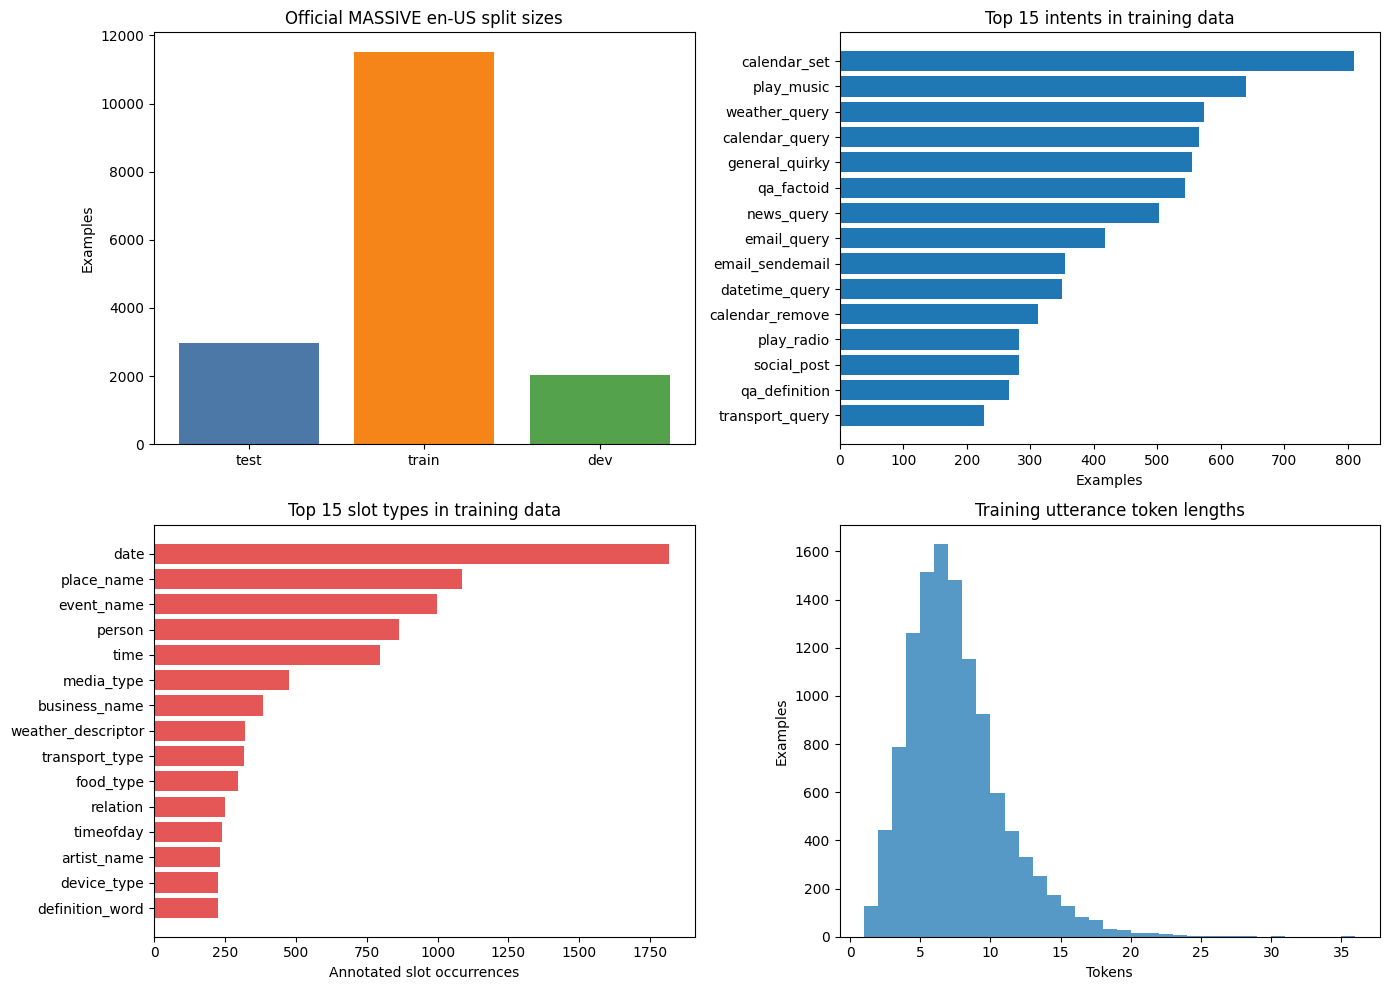

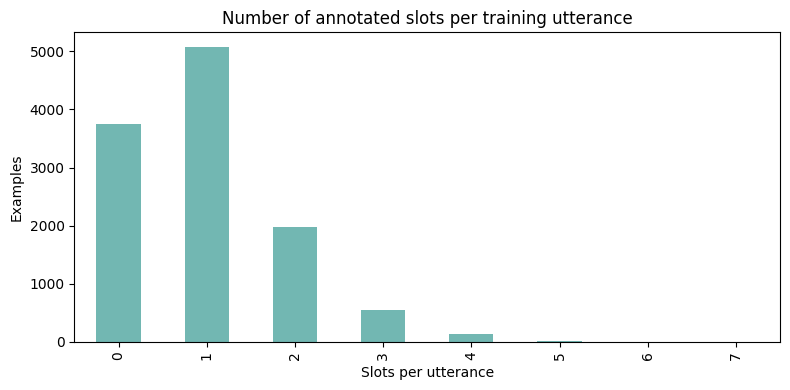

Observation: the long-tailed intent and slot distributions motivate micro-F1 reporting, while dynamic padding and packed sequences avoid work on the many short utterances. Offset-preserving tokenization is necessary for multi-word and punctuation-adjacent slots.


In [3]:
SLOT_PATTERN = re.compile(r"\[([A-Za-z0-9_]+)\s*:\s*(.*?)\]")
TOKEN_PATTERN = re.compile(r"\w+(?:['’]\w+)*|[^\w\s]", flags=re.UNICODE)


def parse_slot_annotations(record_or_utt, annot_utt: str | None = None):
    """Parse MASSIVE bracket annotations into exact character spans.

    Returns the reconstructed plain utterance and an occurrence-preserving list
    of dictionaries with type, start, end, and text. Any mismatch is fatal.
    """
    if isinstance(record_or_utt, dict):
        utt = record_or_utt["utt"]
        annotated = record_or_utt["annot_utt"]
        record_id = record_or_utt.get("id", "unknown")
    else:
        utt = record_or_utt
        annotated = annot_utt
        record_id = "manual"
    if annotated is None:
        raise ValueError("annot_utt is required")
    parts, spans = [], []
    annotated_cursor = 0
    plain_cursor = 0
    for match in SLOT_PATTERN.finditer(annotated):
        literal = annotated[annotated_cursor:match.start()]
        parts.append(literal)
        plain_cursor += len(literal)
        slot_type = match.group(1)
        slot_text = match.group(2)
        start = plain_cursor
        end = start + len(slot_text)
        parts.append(slot_text)
        spans.append({"type": slot_type, "start": start, "end": end, "text": slot_text})
        plain_cursor = end
        annotated_cursor = match.end()
    tail = annotated[annotated_cursor:]
    parts.append(tail)
    reconstructed = "".join(parts)
    if reconstructed != utt:
        raise ValueError(
            f"Annotation reconstruction failed for record {record_id}:\n"
            f"utt={utt!r}\nannot_utt={annotated!r}\nreconstructed={reconstructed!r}"
        )
    for span in spans:
        assert 0 <= span["start"] < span["end"] <= len(utt)
        assert utt[span["start"]:span["end"]] == span["text"]
    return reconstructed, spans


def tokenize_with_offsets(utterance: str):
    """Deterministic Unicode-aware word/punctuation tokenization with offsets."""
    matches = list(TOKEN_PATTERN.finditer(utterance))
    return [match.group(0) for match in matches], [(match.start(), match.end()) for match in matches]


parsed_all = {record["id"]: parse_slot_annotations(record)[1] for record in all_data}
official_intents = sorted({record["intent"] for record in all_data})
official_slot_types = sorted({span["type"] for spans in parsed_all.values() for span in spans})
assert len(official_intents) == 60
assert len(official_slot_types) == 55

train_intent_counts = Counter(record["intent"] for record in train_data)
train_slot_counts = Counter(
    span["type"] for record in train_data for span in parsed_all[record["id"]]
)
train_lengths = [len(tokenize_with_offsets(record["utt"])[0]) for record in train_data]
train_slot_numbers = [len(parsed_all[record["id"]]) for record in train_data]

print(f"Unique intents in official inventory: {len(official_intents)}")
print(f"Unique slot types in official inventory: {len(official_slot_types)}")
print("Most frequent training intents:", train_intent_counts.most_common(8))
print("Least frequent training intents:", sorted(train_intent_counts.items(), key=lambda pair: pair[1])[:8])
print("Most frequent training slot types:", train_slot_counts.most_common(10))
print("Least frequent training slot types:", sorted(train_slot_counts.items(), key=lambda pair: pair[1])[:10])
print(
    "Training token lengths - "
    f"mean={np.mean(train_lengths):.2f}, median={np.median(train_lengths):.2f}, "
    f"min={min(train_lengths)}, max={max(train_lengths)}"
)
no_slot_percentage = 100.0 * sum(count == 0 for count in train_slot_numbers) / len(train_slot_numbers)
print(f"Training examples with no slots: {no_slot_percentage:.2f}%")

multi_slot_examples = [record for record in train_data if len(parsed_all[record["id"]]) >= 2][:3]
multiword_examples = [
    record for record in train_data
    if any(" " in span["text"] for span in parsed_all[record["id"]])
][:3]
punctuation_examples = [
    record for record in train_data
    if re.search(r"[^\w\s']", record["utt"])
][:3]
print("\nMultiple-slot examples:")
for example in multi_slot_examples:
    print(" -", example["annot_utt"])
print("\nMulti-word slot examples:")
for example in multiword_examples:
    print(" -", example["annot_utt"])
print("\nPunctuation-sensitive examples:")
for example in punctuation_examples:
    print(" -", example["annot_utt"])

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0, 0].bar(partition_counts.keys(), partition_counts.values(), color=["#4C78A8", "#F58518", "#54A24B"])
axes[0, 0].set_title("Official MASSIVE en-US split sizes")
axes[0, 0].set_ylabel("Examples")

top_intents = train_intent_counts.most_common(15)
axes[0, 1].barh([name for name, _ in reversed(top_intents)], [count for _, count in reversed(top_intents)])
axes[0, 1].set_title("Top 15 intents in training data")
axes[0, 1].set_xlabel("Examples")

top_slots = train_slot_counts.most_common(15)
axes[1, 0].barh([name for name, _ in reversed(top_slots)], [count for _, count in reversed(top_slots)], color="#E45756")
axes[1, 0].set_title("Top 15 slot types in training data")
axes[1, 0].set_xlabel("Annotated slot occurrences")

axes[1, 1].hist(train_lengths, bins=range(1, max(train_lengths) + 2), alpha=0.75, label="token length")
axes[1, 1].set_title("Training utterance token lengths")
axes[1, 1].set_xlabel("Tokens")
axes[1, 1].set_ylabel("Examples")
plt.tight_layout()
plt.show()

slot_number_series = pd.Series(train_slot_numbers).value_counts().sort_index()
ax = slot_number_series.plot(kind="bar", figsize=(8, 4), color="#72B7B2")
ax.set_title("Number of annotated slots per training utterance")
ax.set_xlabel("Slots per utterance")
ax.set_ylabel("Examples")
plt.tight_layout()
plt.show()

print(
    "Observation: the long-tailed intent and slot distributions motivate micro-F1 reporting, "
    "while dynamic padding and packed sequences avoid work on the many short utterances. "
    "Offset-preserving tokenization is necessary for multi-word and punctuation-adjacent slots."
)

## 4. Offset-preserving preprocessing and BIO supervision

The parser first reconstructs the unannotated string from `annot_utt` and checks it against `utt`. The original utterance is then tokenized with regex match offsets. A slot is accepted only when its character boundaries exactly equal the outer boundaries of its assigned tokens; failures raise diagnostics rather than dropping records.

Vocabulary counts come from training tokens only. `<PAD>` and `<UNK>` are the only special tokens. The official label inventory is sorted for deterministic mappings. Inspecting the released label inventory is not fitting from dev/test examples; vocabulary and learned parameters remain train-only.

In [4]:
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"
PAD_ID = 0
UNK_ID = 1
SLOT_PAD_ID = -100


def spans_to_bio(utterance: str, offsets, spans):
    """Align exact character spans to tokens and return BIO strings."""
    labels = ["O"] * len(offsets)
    for span in spans:
        token_indices = [
            index for index, (start, end) in enumerate(offsets)
            if start >= span["start"] and end <= span["end"]
        ]
        if not token_indices:
            raise ValueError(f"No token aligned to slot span {span} in {utterance!r}")
        first, last = token_indices[0], token_indices[-1]
        if offsets[first][0] != span["start"] or offsets[last][1] != span["end"]:
            raise ValueError(
                f"Slot boundary is not a token boundary: span={span}, "
                f"tokens={[(utterance[s:e], s, e) for s, e in offsets]}"
            )
        if any(labels[index] != "O" for index in token_indices):
            raise ValueError(f"Overlapping slot annotations are unsupported: {spans}")
        labels[first] = f"B-{span['type']}"
        for index in token_indices[1:]:
            labels[index] = f"I-{span['type']}"
    return labels


def prepare_record(record):
    _, spans = parse_slot_annotations(record)
    tokens, offsets = tokenize_with_offsets(record["utt"])
    if not tokens:
        raise ValueError(f"Record {record.get('id')} produced no tokens")
    bio_labels = spans_to_bio(record["utt"], offsets, spans)
    return {
        "id": record["id"],
        "partition": record["partition"],
        "utt": record["utt"],
        "intent": record["intent"],
        "tokens": tokens,
        "offsets": offsets,
        "bio_labels": bio_labels,
        "gold_spans": [(span["type"], span["start"], span["end"]) for span in spans],
    }


prepared_all = [prepare_record(record) for record in all_data]
prepared_by_id = {example["id"]: example for example in prepared_all}
prepared_train = [prepared_by_id[record["id"]] for record in train_data]
prepared_dev = [prepared_by_id[record["id"]] for record in dev_data]
prepared_test = [prepared_by_id[record["id"]] for record in test_data]
assert len(prepared_all) == len(all_data)
assert len(prepared_train) == 11514 and len(prepared_dev) == 2033 and len(prepared_test) == 2974


def build_vocabulary(training_examples, min_frequency=1, max_size=None):
    counts = Counter(token for example in training_examples for token in example["tokens"])
    ordered = sorted(counts.items(), key=lambda pair: (-pair[1], pair[0]))
    ordered = [pair for pair in ordered if pair[1] >= min_frequency]
    if max_size is not None:
        ordered = ordered[: max(0, max_size - 2)]
    vocabulary = {PAD_TOKEN: PAD_ID, UNK_TOKEN: UNK_ID}
    vocabulary.update({token: index + 2 for index, (token, _) in enumerate(ordered)})
    return vocabulary, counts


vocab, train_token_counts = build_vocabulary(
    prepared_train,
    CONFIG["min_token_frequency"],
    CONFIG["max_vocab_size"],
)
intent_to_id = {label: index for index, label in enumerate(official_intents)}
id_to_intent = {index: label for label, index in intent_to_id.items()}
bio_labels = ["O"] + [prefix + slot for slot in official_slot_types for prefix in ("B-", "I-")]
bio_to_id = {label: index for index, label in enumerate(bio_labels)}
id_to_bio = {index: label for label, index in bio_to_id.items()}
assert len(intent_to_id) == 60
assert len(bio_to_id) == 111


def encode_example(example):
    encoded = dict(example)
    encoded["word_ids"] = [vocab.get(token, UNK_ID) for token in example["tokens"]]
    encoded["length"] = len(encoded["word_ids"])
    encoded["intent_id"] = intent_to_id[example["intent"]]
    encoded["bio_ids"] = [bio_to_id[label] for label in example["bio_labels"]]
    return encoded


encoded_train = [encode_example(example) for example in prepared_train]
encoded_dev = [encode_example(example) for example in prepared_dev]
encoded_test = [encode_example(example) for example in prepared_test]

print(f"Training vocabulary size (including specials): {len(vocab):,}")
for name, examples in (("train", encoded_train), ("dev", encoded_dev), ("test", encoded_test)):
    token_total = sum(example["length"] for example in examples)
    unk_total = sum(token_id == UNK_ID for example in examples for token_id in example["word_ids"])
    print(f"{name:>5} UNK rate: {100.0 * unk_total / token_total:.2f}% ({unk_total:,}/{token_total:,})")

# Essential corpus-wide alignment checks: decode of gold BIO must be exact.
def decode_bio_spans(bio_sequence, offsets, utterance):
    """Decode BIO tags to occurrence-aware (type, start, end) spans.

    Invalid I-X transitions are repaired deterministically as B-X. This policy is
    applied identically to gold checks and predictions.
    """
    decoded = []
    active_type = None
    active_start = None
    active_end = None

    def close_active():
        nonlocal active_type, active_start, active_end
        if active_type is not None:
            decoded.append((active_type, active_start, active_end))
        active_type = active_start = active_end = None

    for label, (start, end) in zip(bio_sequence, offsets):
        if label == "O":
            close_active()
            continue
        if "-" not in label:
            raise ValueError(f"Malformed BIO label: {label!r}")
        prefix, slot_type = label.split("-", 1)
        if prefix == "B":
            close_active()
            active_type, active_start, active_end = slot_type, start, end
        elif prefix == "I":
            if active_type == slot_type:
                active_end = end
            else:
                close_active()  # invalid I transition becomes a new B span
                active_type, active_start, active_end = slot_type, start, end
        else:
            raise ValueError(f"Malformed BIO prefix: {prefix!r}")
    close_active()
    for slot_type, start, end in decoded:
        assert 0 <= start < end <= len(utterance)
    return decoded


for example in prepared_all:
    decoded_gold = decode_bio_spans(example["bio_labels"], example["offsets"], example["utt"])
    if Counter(decoded_gold) != Counter(example["gold_spans"]):
        raise AssertionError(
            f"Gold BIO round-trip failed for {example['id']}: "
            f"expected={example['gold_spans']}, decoded={decoded_gold}"
        )
print(f"Passed reconstruction, boundary, and gold BIO round-trip checks for all {len(prepared_all):,} examples.")

# Targeted synthetic checks for multi-token spans, punctuation, and repeated words.
synthetic_cases = [
    ("set it for five thirty", [{"type": "time", "start": 11, "end": 22, "text": "five thirty"}]),
    ("play hello, world", [{"type": "song_name", "start": 5, "end": 17, "text": "hello, world"}]),
    ("red then red", [{"type": "color_type", "start": 9, "end": 12, "text": "red"}]),
]
for utterance, spans in synthetic_cases:
    tokens, offsets = tokenize_with_offsets(utterance)
    tags = spans_to_bio(utterance, offsets, spans)
    expected = [(span["type"], span["start"], span["end"]) for span in spans]
    assert decode_bio_spans(tags, offsets, utterance) == expected
print("Passed targeted multi-token, punctuation, and repeated-word alignment tests.")

Training vocabulary size (including specials): 5,294
train UNK rate: 0.00% (0/81,120)
  dev UNK rate: 3.27% (464/14,182)
 test UNK rate: 3.46% (712/20,571)
Passed reconstruction, boundary, and gold BIO round-trip checks for all 16,521 examples.
Passed targeted multi-token, punctuation, and repeated-word alignment tests.


## 5. GloVe 6B 300-dimensional initialization

Only vectors needed by the training vocabulary are retained. Exact-token lookup is attempted first, followed by a lowercase lookup. OOV rows use seeded random normal initialization; `<PAD>` is zero. The embedding table remains trainable and counts toward the 20M limit.

In [5]:
GLOVE_URL = "https://nlp.stanford.edu/data/glove.6B.zip"
GLOVE_ARCHIVE = DOWNLOAD_DIR / "glove.6B.zip"
GLOVE_PATH = DATA_DIR / "glove" / "glove.6B.300d.txt"


def ensure_glove_300d() -> Path:
    if GLOVE_PATH.exists():
        print(f"Using existing GloVe file: {GLOVE_PATH}")
        return GLOVE_PATH
    download_file(GLOVE_URL, GLOVE_ARCHIVE)
    member_name = "glove.6B.300d.txt"
    with zipfile.ZipFile(GLOVE_ARCHIVE) as archive:
        if member_name not in archive.namelist():
            raise RuntimeError(f"{member_name!r} is absent from {GLOVE_ARCHIVE}")
        GLOVE_PATH.parent.mkdir(parents=True, exist_ok=True)
        temporary = GLOVE_PATH.with_suffix(".txt.part")
        with archive.open(member_name) as source, temporary.open("wb") as output:
            shutil.copyfileobj(source, output)
        temporary.replace(GLOVE_PATH)
    return GLOVE_PATH


def build_embedding_matrix(vocabulary, glove_path, dimension, seed):
    """Stream GloVe and keep only vectors needed for the training vocabulary."""
    rng = np.random.default_rng(seed)
    matrix = rng.normal(0.0, 0.05, size=(len(vocabulary), dimension)).astype(np.float32)
    matrix[PAD_ID] = 0.0
    exact_needed = set(vocabulary) - {PAD_TOKEN, UNK_TOKEN}
    lowercase_to_tokens = collections.defaultdict(list)
    for token in exact_needed:
        lowercase_to_tokens[token.lower()].append(token)
    found_tokens = set()
    with Path(glove_path).open("r", encoding="utf-8") as handle:
        for line_number, line in enumerate(handle, start=1):
            pieces = line.rstrip().split(" ")
            word, values = pieces[0], pieces[1:]
            if word not in exact_needed and word not in lowercase_to_tokens:
                continue
            if len(values) != dimension:
                raise ValueError(f"GloVe dimension error on line {line_number}")
            vector = np.asarray(values, dtype=np.float32)
            if word in exact_needed and word not in found_tokens:
                matrix[vocabulary[word]] = vector
                found_tokens.add(word)
            for original_token in lowercase_to_tokens.get(word, []):
                if original_token not in found_tokens:
                    matrix[vocabulary[original_token]] = vector
                    found_tokens.add(original_token)
    matchable = len(vocabulary) - 2
    matched = len(found_tokens)
    return matrix, {
        "vocabulary_size": len(vocabulary),
        "embedding_dimension": dimension,
        "matched_tokens": matched,
        "unmatched_tokens": matchable - matched,
        "coverage_percent": 100.0 * matched / matchable if matchable else 0.0,
        "source": "GloVe 6B 300d",
        "fine_tuned": CONFIG["fine_tune_embeddings"],
    }


glove_path = ensure_glove_300d()
embedding_matrix, embedding_info = build_embedding_matrix(
    vocab, glove_path, CONFIG["embedding_dim"], CONFIG["seed"]
)
print(json.dumps(embedding_info, indent=2))

Using existing download: C:\Users\envy\OneDrive\Documents\Desktop\NLP\data\downloads\glove.6B.zip


{
  "vocabulary_size": 5294,
  "embedding_dimension": 300,
  "matched_tokens": 4914,
  "unmatched_tokens": 378,
  "coverage_percent": 92.85714285714286,
  "source": "GloVe 6B 300d",
  "fine_tuned": true
}


## 6. Shared exact-span evaluation functions

Slot evaluation uses occurrence-aware `(slot_type, character_start, character_end)` tuples and `Counter` intersections. Thus identical text at different offsets is distinct, duplicate occurrences are retained, and partial boundaries never match. If an evaluated collection has no gold or predicted slots at all, its slot F1 is defined as 100% (perfect empty prediction); any false positive makes it 0%.

In [6]:
def compute_intent_accuracy(predicted_ids, gold_ids):
    if len(predicted_ids) != len(gold_ids) or not gold_ids:
        raise ValueError("Intent predictions and gold labels must have equal non-zero length")
    return 100.0 * sum(pred == gold for pred, gold in zip(predicted_ids, gold_ids)) / len(gold_ids)


def slot_counts(predicted_spans_by_example, gold_spans_by_example):
    if len(predicted_spans_by_example) != len(gold_spans_by_example):
        raise ValueError("Predicted and gold slot collections must have equal length")
    true_positive = false_positive = false_negative = 0
    for predicted, gold in zip(predicted_spans_by_example, gold_spans_by_example):
        predicted_counter = Counter(map(tuple, predicted))
        gold_counter = Counter(map(tuple, gold))
        matches = sum((predicted_counter & gold_counter).values())
        true_positive += matches
        false_positive += sum(predicted_counter.values()) - matches
        false_negative += sum(gold_counter.values()) - matches
    return true_positive, false_positive, false_negative


def compute_slot_micro_f1(predicted_spans_by_example, gold_spans_by_example):
    tp, fp, fn = slot_counts(predicted_spans_by_example, gold_spans_by_example)
    denominator = 2 * tp + fp + fn
    return 100.0 if denominator == 0 else 100.0 * (2 * tp) / denominator


def compute_combined_score(intent_accuracy, slot_micro_f1):
    return (intent_accuracy + slot_micro_f1) / 2.0


# Hand-constructed metric unit tests.
assert compute_intent_accuracy([1], [1]) == 100.0
assert compute_intent_accuracy([1, 0], [1, 1]) == 50.0
exact = [[("time", 3, 10)]]
assert compute_slot_micro_f1(exact, exact) == 100.0
assert compute_slot_micro_f1([[("time", 3, 9)]], exact) == 0.0  # wrong boundary
assert compute_slot_micro_f1([[('date', 3, 10)]], exact) == 0.0  # wrong type
assert math.isclose(
    compute_slot_micro_f1([[('time', 3, 10), ('date', 12, 18)]], exact), 200 / 3
)
assert compute_slot_micro_f1([[]], [[]]) == 100.0
assert compute_slot_micro_f1([[('time', 0, 2)]], [[]]) == 0.0
duplicate_gold = [[("color", 0, 3), ("color", 8, 11)]]
assert compute_slot_micro_f1(duplicate_gold, duplicate_gold) == 100.0
assert math.isclose(compute_slot_micro_f1([[('color', 0, 3)]], duplicate_gold), 200 / 3)

# Invalid I transitions are deterministically repaired as a B of the same type.
invalid_i = decode_bio_spans(["I-color", "I-color"], [(0, 3), (4, 7)], "red red")
assert invalid_i == [("color", 0, 7)]
switched_i = decode_bio_spans(["B-time", "I-date"], [(0, 3), (4, 7)], "one day")
assert switched_i == [("time", 0, 3), ("date", 4, 7)]
print("All intent, exact-span slot, empty-case, duplicate-occurrence, and invalid-BIO tests passed.")

All intent, exact-span slot, empty-case, duplicate-occurrence, and invalid-BIO tests passed.


## 7. Dynamic batching and joint Stage 1 BiLSTM (300D controlled baseline)

`pack_padded_sequence` avoids recurrent computation over padding. Masked mean pooling feeds the intent head; every non-padding contextual token feeds the BIO head. There is exactly one embedding table and one shared BiLSTM encoder. Explicit dropout is used because PyTorch's LSTM inter-layer dropout is inactive when `num_layers=1`.

In [7]:
class MassiveJointDataset(Dataset):
    def __init__(self, encoded_examples):
        self.examples = encoded_examples

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, index):
        return self.examples[index]


def collate_batch(examples):
    batch_size = len(examples)
    max_length = max(example["length"] for example in examples)
    input_ids = torch.full((batch_size, max_length), PAD_ID, dtype=torch.long)
    bio_ids = torch.full((batch_size, max_length), SLOT_PAD_ID, dtype=torch.long)
    lengths = torch.tensor([example["length"] for example in examples], dtype=torch.long)
    intent_ids = torch.tensor([example["intent_id"] for example in examples], dtype=torch.long)
    for row, example in enumerate(examples):
        length = example["length"]
        input_ids[row, :length] = torch.tensor(example["word_ids"], dtype=torch.long)
        bio_ids[row, :length] = torch.tensor(example["bio_ids"], dtype=torch.long)
    attention_mask = input_ids.ne(PAD_ID)
    return {
        "input_ids": input_ids,
        "bio_ids": bio_ids,
        "lengths": lengths,
        "intent_ids": intent_ids,
        "attention_mask": attention_mask,
        "examples": examples,
    }


train_generator = torch.Generator().manual_seed(CONFIG["seed"])
train_loader = DataLoader(
    MassiveJointDataset(encoded_train), batch_size=CONFIG["batch_size"], shuffle=True,
    num_workers=CONFIG["num_workers"], collate_fn=collate_batch, generator=train_generator,
)
dev_loader = DataLoader(
    MassiveJointDataset(encoded_dev), batch_size=CONFIG["batch_size"], shuffle=False,
    num_workers=CONFIG["num_workers"], collate_fn=collate_batch,
)
test_loader = DataLoader(
    MassiveJointDataset(encoded_test), batch_size=CONFIG["batch_size"], shuffle=False,
    num_workers=CONFIG["num_workers"], collate_fn=collate_batch,
)


class JointBiLSTM(nn.Module):
    """One shared BiLSTM with intent and token-level BIO heads."""
    def __init__(
        self, vocab_size, embedding_dim, hidden_dim, num_layers, dropout,
        num_intents, num_bio_labels, pretrained_embeddings=None,
        fine_tune_embeddings=True,
    ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD_ID)
        if pretrained_embeddings is not None:
            tensor = torch.as_tensor(pretrained_embeddings, dtype=torch.float32)
            if tuple(tensor.shape) != (vocab_size, embedding_dim):
                raise ValueError(f"Unexpected embedding shape: {tuple(tensor.shape)}")
            with torch.no_grad():
                self.embedding.weight.copy_(tensor)
        self.embedding.weight.requires_grad = fine_tune_embeddings
        self.embedding_dropout = nn.Dropout(dropout)
        self.encoder = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        encoder_dim = 2 * hidden_dim
        self.output_dropout = nn.Dropout(dropout)
        self.intent_head = nn.Linear(encoder_dim, num_intents)
        self.slot_head = nn.Linear(encoder_dim, num_bio_labels)

    def forward(self, input_ids, lengths, attention_mask):
        embedded = self.embedding_dropout(self.embedding(input_ids))
        packed = pack_padded_sequence(
            embedded, lengths.detach().cpu(), batch_first=True, enforce_sorted=False
        )
        packed_output, _ = self.encoder(packed)
        encoded, _ = pad_packed_sequence(
            packed_output, batch_first=True, total_length=input_ids.size(1)
        )
        encoded = self.output_dropout(encoded)
        mask = attention_mask.unsqueeze(-1).to(encoded.dtype)
        pooled = (encoded * mask).sum(dim=1) / mask.sum(dim=1).clamp_min(1.0)
        return self.intent_head(pooled), self.slot_head(encoded)


def make_model(pretrained=True):
    return JointBiLSTM(
        vocab_size=len(vocab),
        embedding_dim=CONFIG["embedding_dim"],
        hidden_dim=CONFIG["hidden_dim"],
        num_layers=CONFIG["num_layers"],
        dropout=CONFIG["dropout"],
        num_intents=len(intent_to_id),
        num_bio_labels=len(bio_to_id),
        pretrained_embeddings=embedding_matrix if pretrained else None,
        fine_tune_embeddings=CONFIG["fine_tune_embeddings"],
    )


def parameter_report(model):
    groups = {
        "Embedding": sum(parameter.numel() for parameter in model.embedding.parameters()),
        "Shared BiLSTM": sum(parameter.numel() for parameter in model.encoder.parameters()),
        "Intent head": sum(parameter.numel() for parameter in model.intent_head.parameters()),
        "Slot head": sum(parameter.numel() for parameter in model.slot_head.parameters()),
    }
    total = sum(parameter.numel() for parameter in model.parameters())
    trainable = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
    for name, count in groups.items():
        print(f"{name:>15}: {count:,}")
    print(f"{'Total':>15}: {total:,}")
    print(f"{'Trainable':>15}: {trainable:,}")
    assert total <= 20_000_000, f"Parameter cap exceeded: {total:,}"
    return groups, total, trainable


seed_everything(CONFIG["seed"])
model = make_model(pretrained=True).to(DEVICE)
parameter_groups, total_parameters, trainable_parameters = parameter_report(model)

      Embedding: 1,588,200
  Shared BiLSTM: 440,320
    Intent head: 15,420
      Slot head: 28,527
          Total: 2,072,467
      Trainable: 2,072,467


## 8. Training and evaluation implementation

The total loss is the unweighted sum of intent cross-entropy and slot-token cross-entropy. Padded slot positions use `ignore_index=-100`. AdamW, gradient clipping, evaluation mode, and inference mode are applied explicitly. All three validation metrics are retained independently.

In [8]:
intent_criterion = nn.CrossEntropyLoss()
slot_criterion = nn.CrossEntropyLoss(ignore_index=SLOT_PAD_ID)


def move_batch_to_device(batch, device):
    return {
        key: value.to(device) if torch.is_tensor(value) else value
        for key, value in batch.items()
    }


def compute_joint_loss(intent_logits, slot_logits, batch):
    intent_loss = intent_criterion(intent_logits, batch["intent_ids"])
    slot_loss = slot_criterion(
        slot_logits.reshape(-1, slot_logits.size(-1)), batch["bio_ids"].reshape(-1)
    )
    return intent_loss + slot_loss, intent_loss, slot_loss


def train_one_epoch(model, loader, optimizer, device, gradient_clip_norm):
    model.train()
    sums = Counter()
    batch_count = 0
    for raw_batch in loader:
        batch = move_batch_to_device(raw_batch, device)
        optimizer.zero_grad(set_to_none=True)
        intent_logits, slot_logits = model(
            batch["input_ids"], batch["lengths"], batch["attention_mask"]
        )
        total_loss, intent_loss, slot_loss = compute_joint_loss(intent_logits, slot_logits, batch)
        if not torch.isfinite(total_loss):
            raise FloatingPointError(f"Non-finite training loss: {total_loss.item()}")
        total_loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), gradient_clip_norm)
        optimizer.step()
        sums.update({
            "total_loss": total_loss.item(),
            "intent_loss": intent_loss.item(),
            "slot_loss": slot_loss.item(),
        })
        batch_count += 1
    return {key: value / batch_count for key, value in sums.items()}


def evaluate_model(model, loader, device, return_predictions=False):
    model.eval()
    sums = Counter()
    batch_count = 0
    predicted_intents, gold_intents = [], []
    predicted_spans, gold_spans = [], []
    ordered_examples = []
    with torch.inference_mode():
        for raw_batch in loader:
            batch = move_batch_to_device(raw_batch, device)
            intent_logits, slot_logits = model(
                batch["input_ids"], batch["lengths"], batch["attention_mask"]
            )
            total_loss, intent_loss, slot_loss = compute_joint_loss(intent_logits, slot_logits, batch)
            sums.update({
                "total_loss": total_loss.item(),
                "intent_loss": intent_loss.item(),
                "slot_loss": slot_loss.item(),
            })
            batch_count += 1
            intent_predictions = intent_logits.argmax(dim=-1).cpu().tolist()
            slot_predictions = slot_logits.argmax(dim=-1).cpu().tolist()
            predicted_intents.extend(intent_predictions)
            gold_intents.extend(raw_batch["intent_ids"].tolist())
            for row, example in enumerate(raw_batch["examples"]):
                length = example["length"]
                labels = [id_to_bio[index] for index in slot_predictions[row][:length]]
                spans = decode_bio_spans(labels, example["offsets"], example["utt"])
                predicted_spans.append(spans)
                gold_spans.append(example["gold_spans"])
                ordered_examples.append(example)
    intent_accuracy = compute_intent_accuracy(predicted_intents, gold_intents)
    slot_micro_f1 = compute_slot_micro_f1(predicted_spans, gold_spans)
    result = {
        "total_loss": sums["total_loss"] / batch_count,
        "intent_loss": sums["intent_loss"] / batch_count,
        "slot_loss": sums["slot_loss"] / batch_count,
        "intent_accuracy": intent_accuracy,
        "slot_micro_f1": slot_micro_f1,
        "combined_score": compute_combined_score(intent_accuracy, slot_micro_f1),
    }
    if return_predictions:
        result["predicted_intents"] = predicted_intents
        result["gold_intents"] = gold_intents
        result["predicted_spans"] = predicted_spans
        result["gold_spans"] = gold_spans
        result["examples"] = ordered_examples
    return result

## 9. CPU diagnostics and one-epoch benchmark

A forward/backward smoke test checks shapes, masks, and finite loss. A fresh diagnostic model is trained repeatedly on one training batch to confirm learnability. A separate fresh model benchmarks one complete training epoch. Both are discarded, the seed is reset, and a newly initialized model is used for the official run.

In [9]:
first_raw_batch = next(iter(train_loader))
first_batch = move_batch_to_device(first_raw_batch, DEVICE)
diagnostic_model = make_model(pretrained=True).to(DEVICE)
diagnostic_model.train()
intent_logits, slot_logits = diagnostic_model(
    first_batch["input_ids"], first_batch["lengths"], first_batch["attention_mask"]
)
assert intent_logits.shape == (len(first_raw_batch["examples"]), len(intent_to_id))
assert slot_logits.shape == (
    len(first_raw_batch["examples"]), first_raw_batch["input_ids"].shape[1], len(bio_to_id)
)
assert torch.equal(first_raw_batch["attention_mask"].sum(dim=1), first_raw_batch["lengths"])
smoke_total, smoke_intent, smoke_slot = compute_joint_loss(intent_logits, slot_logits, first_batch)
assert all(torch.isfinite(loss) for loss in (smoke_total, smoke_intent, smoke_slot))
smoke_total.backward()
assert any(parameter.grad is not None for parameter in diagnostic_model.parameters())
print(
    f"Forward/backward passed: intent logits={tuple(intent_logits.shape)}, "
    f"slot logits={tuple(slot_logits.shape)}, loss={smoke_total.item():.4f}"
)

# One-batch overfit diagnostic; uses training examples only.
diagnostic_model = make_model(pretrained=True).to(DEVICE)
diagnostic_optimizer = torch.optim.AdamW(diagnostic_model.parameters(), lr=1e-2)
diagnostic_losses = []
for step in range(CONFIG["diagnostic_steps"]):
    diagnostic_model.train()
    diagnostic_optimizer.zero_grad(set_to_none=True)
    intent_logits, slot_logits = diagnostic_model(
        first_batch["input_ids"], first_batch["lengths"], first_batch["attention_mask"]
    )
    total_loss, _, _ = compute_joint_loss(intent_logits, slot_logits, first_batch)
    total_loss.backward()
    nn.utils.clip_grad_norm_(diagnostic_model.parameters(), CONFIG["gradient_clip_norm"])
    diagnostic_optimizer.step()
    diagnostic_losses.append(total_loss.item())
assert diagnostic_losses[-1] < diagnostic_losses[0], diagnostic_losses
print(
    f"One-batch overfit diagnostic passed: {diagnostic_losses[0]:.4f} -> "
    f"{diagnostic_losses[-1]:.4f} over {CONFIG['diagnostic_steps']} steps"
)
del diagnostic_model, diagnostic_optimizer, intent_logits, slot_logits
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Full one-epoch benchmark on a throwaway model.
seed_everything(CONFIG["seed"])
benchmark_model = make_model(pretrained=True).to(DEVICE)
benchmark_optimizer = torch.optim.AdamW(
    benchmark_model.parameters(), lr=CONFIG["learning_rate"], weight_decay=CONFIG["weight_decay"]
)
benchmark_start = time.perf_counter()
benchmark_losses = train_one_epoch(
    benchmark_model, train_loader, benchmark_optimizer, DEVICE, CONFIG["gradient_clip_norm"]
)
benchmark_epoch_seconds = time.perf_counter() - benchmark_start
estimated_official_minutes = benchmark_epoch_seconds * CONFIG["max_epochs"] / 60.0
print(f"Benchmark epoch losses: {benchmark_losses}")
print(f"Measured full training epoch: {benchmark_epoch_seconds:.2f} seconds")
print(
    f"Estimated upper-bound time for {CONFIG['max_epochs']} official epochs: "
    f"{estimated_official_minutes:.1f} minutes (validation overhead excluded)"
)
del benchmark_model, benchmark_optimizer
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Reset all trainable state and RNGs before official training.
seed_everything(CONFIG["seed"])
train_generator.manual_seed(CONFIG["seed"])
model = make_model(pretrained=True).to(DEVICE)
parameter_groups, total_parameters, trainable_parameters = parameter_report(model)

Forward/backward passed: intent logits=(32, 60), slot logits=(32, 16, 111), loss=8.7721


One-batch overfit diagnostic passed: 8.8362 -> 0.0021 over 40 steps


Benchmark epoch losses: {'total_loss': 3.34386345744133, 'intent_loss': 2.28469746808211, 'slot_loss': 1.0591659827364817}
Measured full training epoch: 28.78 seconds
Estimated upper-bound time for 20 official epochs: 9.6 minutes (validation overhead excluded)


      Embedding: 1,588,200
  Shared BiLSTM: 440,320
    Intent head: 15,420
      Slot head: 28,527
          Total: 2,072,467
      Trainable: 2,072,467


## 10. Full Stage 1 training and validation-only checkpoint selection

The best checkpoint maximizes `(validation intent accuracy + validation slot micro-F1) / 2`. This combined score is a selection criterion, not a replacement for either official metric. Early stopping patience is four epochs. The test loader is not touched in this section.

In [10]:
CHECKPOINT_PATH = CHECKPOINT_DIR / "baseline_300d_best.pt"
HISTORY_PATH = ARTIFACT_DIR / "baseline_300d_history.csv"


def save_checkpoint(path, model, epoch, validation_metrics, history):
    payload = {
        "model_state_dict": model.state_dict(),
        "epoch": epoch,
        "validation_metrics": validation_metrics,
        "config": dict(CONFIG),
        "vocab": vocab,
        "intent_to_id": intent_to_id,
        "bio_to_id": bio_to_id,
        "embedding_info": embedding_info,
        "total_parameters": total_parameters,
        "trainable_parameters": trainable_parameters,
        "history": history,
    }
    temporary = path.with_suffix(path.suffix + ".tmp")
    torch.save(payload, temporary)
    temporary.replace(path)


optimizer = torch.optim.AdamW(
    model.parameters(), lr=CONFIG["learning_rate"], weight_decay=CONFIG["weight_decay"]
)
history = []
best_score = -math.inf
best_epoch = None
best_validation_metrics = None
epochs_without_improvement = 0
official_training_start = time.perf_counter()

for epoch in range(1, CONFIG["max_epochs"] + 1):
    epoch_start = time.perf_counter()
    train_metrics = train_one_epoch(
        model, train_loader, optimizer, DEVICE, CONFIG["gradient_clip_norm"]
    )
    validation_metrics = evaluate_model(model, dev_loader, DEVICE)
    epoch_seconds = time.perf_counter() - epoch_start
    cumulative_seconds = time.perf_counter() - official_training_start
    record = {
        "epoch": epoch,
        "train_total_loss": train_metrics["total_loss"],
        "train_intent_loss": train_metrics["intent_loss"],
        "train_slot_loss": train_metrics["slot_loss"],
        "val_total_loss": validation_metrics["total_loss"],
        "val_intent_loss": validation_metrics["intent_loss"],
        "val_slot_loss": validation_metrics["slot_loss"],
        "val_intent_accuracy": validation_metrics["intent_accuracy"],
        "val_slot_micro_f1": validation_metrics["slot_micro_f1"],
        "val_combined_score": validation_metrics["combined_score"],
        "epoch_seconds": epoch_seconds,
        "cumulative_seconds": cumulative_seconds,
    }
    history.append(record)
    selection_score = validation_metrics["combined_score"]
    if selection_score > best_score + 1e-12:
        best_score = selection_score
        best_epoch = epoch
        best_validation_metrics = dict(validation_metrics)
        epochs_without_improvement = 0
        save_checkpoint(CHECKPOINT_PATH, model, epoch, best_validation_metrics, history)
    else:
        epochs_without_improvement += 1

    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)
    print(f"\nEpoch {epoch:02d}/{CONFIG['max_epochs']}")
    print(f"Train total loss:  {train_metrics['total_loss']:.6f}")
    print(f"Train intent loss: {train_metrics['intent_loss']:.6f}")
    print(f"Train slot loss:   {train_metrics['slot_loss']:.6f}")
    print(f"Val total loss:    {validation_metrics['total_loss']:.6f}")
    print(f"Val intent loss:   {validation_metrics['intent_loss']:.6f}")
    print(f"Val slot loss:     {validation_metrics['slot_loss']:.6f}")
    print(f"Val intent accuracy: {validation_metrics['intent_accuracy']:.2f}%")
    print(f"Val slot micro-F1:   {validation_metrics['slot_micro_f1']:.2f}%")
    print(f"Val combined score:  {validation_metrics['combined_score']:.2f}%")
    print(f"Epoch time: {epoch_seconds:.2f} seconds; cumulative: {cumulative_seconds:.2f} seconds")
    print(f"Best epoch so far: {best_epoch:02d}")
    if epochs_without_improvement >= CONFIG["patience"]:
        print(f"Early stopping after {CONFIG['patience']} epochs without improvement.")
        break

total_training_seconds = time.perf_counter() - official_training_start
epochs_executed = len(history)
print("\nBEST 300D BASELINE CHECKPOINT")
print(f"Best epoch: {best_epoch}")
print(f"Validation intent accuracy: {best_validation_metrics['intent_accuracy']:.2f}%")
print(f"Validation slot micro-F1: {best_validation_metrics['slot_micro_f1']:.2f}%")
print(f"Validation combined score: {best_validation_metrics['combined_score']:.2f}%")
print(f"Checkpoint: {CHECKPOINT_PATH.name}")
print(f"Total epochs executed: {epochs_executed}")
print(f"Total official training time: {total_training_seconds:.2f} seconds")
print(f"History: {HISTORY_PATH}")


Epoch 01/20
Train total loss:  3.358287
Train intent loss: 2.292322
Train slot loss:   1.065965
Val total loss:    1.632799
Val intent loss:   1.017822
Val slot loss:     0.614977
Val intent accuracy: 74.57%
Val slot micro-F1:   42.50%
Val combined score:  58.54%
Epoch time: 28.94 seconds; cumulative: 28.94 seconds
Best epoch so far: 01



Epoch 02/20
Train total loss:  1.349753
Train intent loss: 0.807106
Train slot loss:   0.542647
Val total loss:    1.135577
Val intent loss:   0.676386
Val slot loss:     0.459191
Val intent accuracy: 81.75%
Val slot micro-F1:   59.41%
Val combined score:  70.58%
Epoch time: 33.74 seconds; cumulative: 62.74 seconds
Best epoch so far: 02



Epoch 03/20
Train total loss:  0.930405
Train intent loss: 0.513780
Train slot loss:   0.416626
Val total loss:    0.959630
Val intent loss:   0.564773
Val slot loss:     0.394858
Val intent accuracy: 85.19%
Val slot micro-F1:   64.83%
Val combined score:  75.01%
Epoch time: 47.31 seconds; cumulative: 110.10 seconds
Best epoch so far: 03



Epoch 04/20
Train total loss:  0.712304
Train intent loss: 0.368093
Train slot loss:   0.344211
Val total loss:    0.903055
Val intent loss:   0.545582
Val slot loss:     0.357473
Val intent accuracy: 85.19%
Val slot micro-F1:   68.79%
Val combined score:  76.99%
Epoch time: 53.18 seconds; cumulative: 163.34 seconds
Best epoch so far: 04



Epoch 05/20
Train total loss:  0.568828
Train intent loss: 0.277121
Train slot loss:   0.291707
Val total loss:    0.880203
Val intent loss:   0.541496
Val slot loss:     0.338707
Val intent accuracy: 84.85%
Val slot micro-F1:   69.90%
Val combined score:  77.37%
Epoch time: 50.57 seconds; cumulative: 213.96 seconds
Best epoch so far: 05


...


Epoch 11/20
Train total loss:  0.222227
Train intent loss: 0.076235
Train slot loss:   0.145992
Val total loss:    0.934324
Val intent loss:   0.620642
Val slot loss:     0.313683
Val intent accuracy: 85.93%
Val slot micro-F1:   75.06%
Val combined score:  80.50%
Epoch time: 48.30 seconds; cumulative: 504.44 seconds
Best epoch so far: 11



Epoch 12/20
Train total loss:  0.195362
Train intent loss: 0.063377
Train slot loss:   0.131985
Val total loss:    0.948821
Val intent loss:   0.638597
Val slot loss:     0.310224
Val intent accuracy: 85.98%
Val slot micro-F1:   74.79%
Val combined score:  80.39%
Epoch time: 51.66 seconds; cumulative: 556.15 seconds
Best epoch so far: 11



Epoch 13/20
Train total loss:  0.178201
Train intent loss: 0.056352
Train slot loss:   0.121850
Val total loss:    0.975379
Val intent loss:   0.658210
Val slot loss:     0.317169
Val intent accuracy: 85.15%
Val slot micro-F1:   74.67%
Val combined score:  79.91%
Epoch time: 59.45 seconds; cumulative: 615.60 seconds
Best epoch so far: 11



Epoch 14/20
Train total loss:  0.161417
Train intent loss: 0.048993
Train slot loss:   0.112424
Val total loss:    0.945179
Val intent loss:   0.635283
Val slot loss:     0.309896
Val intent accuracy: 85.54%
Val slot micro-F1:   75.38%
Val combined score:  80.46%
Epoch time: 58.40 seconds; cumulative: 674.00 seconds
Best epoch so far: 11



Epoch 15/20
Train total loss:  0.142944
Train intent loss: 0.041071
Train slot loss:   0.101872
Val total loss:    0.966457
Val intent loss:   0.649096
Val slot loss:     0.317361
Val intent accuracy: 85.64%
Val slot micro-F1:   74.92%
Val combined score:  80.28%
Epoch time: 45.13 seconds; cumulative: 719.14 seconds
Best epoch so far: 11
Early stopping after 4 epochs without improvement.

BEST 300D BASELINE CHECKPOINT
Best epoch: 11
Validation intent accuracy: 85.93%
Validation slot micro-F1: 75.06%
Validation combined score: 80.50%
Checkpoint: baseline_300d_best.pt
Total epochs executed: 15
Total official training time: 719.14 seconds
History: C:\Users\envy\OneDrive\Documents\Desktop\NLP\artifacts\baseline_300d\baseline_300d_history.csv


## 11. Learning curves

These plots are generated directly from `stage1_history.csv`. The selected epoch is marked by a vertical dashed line.

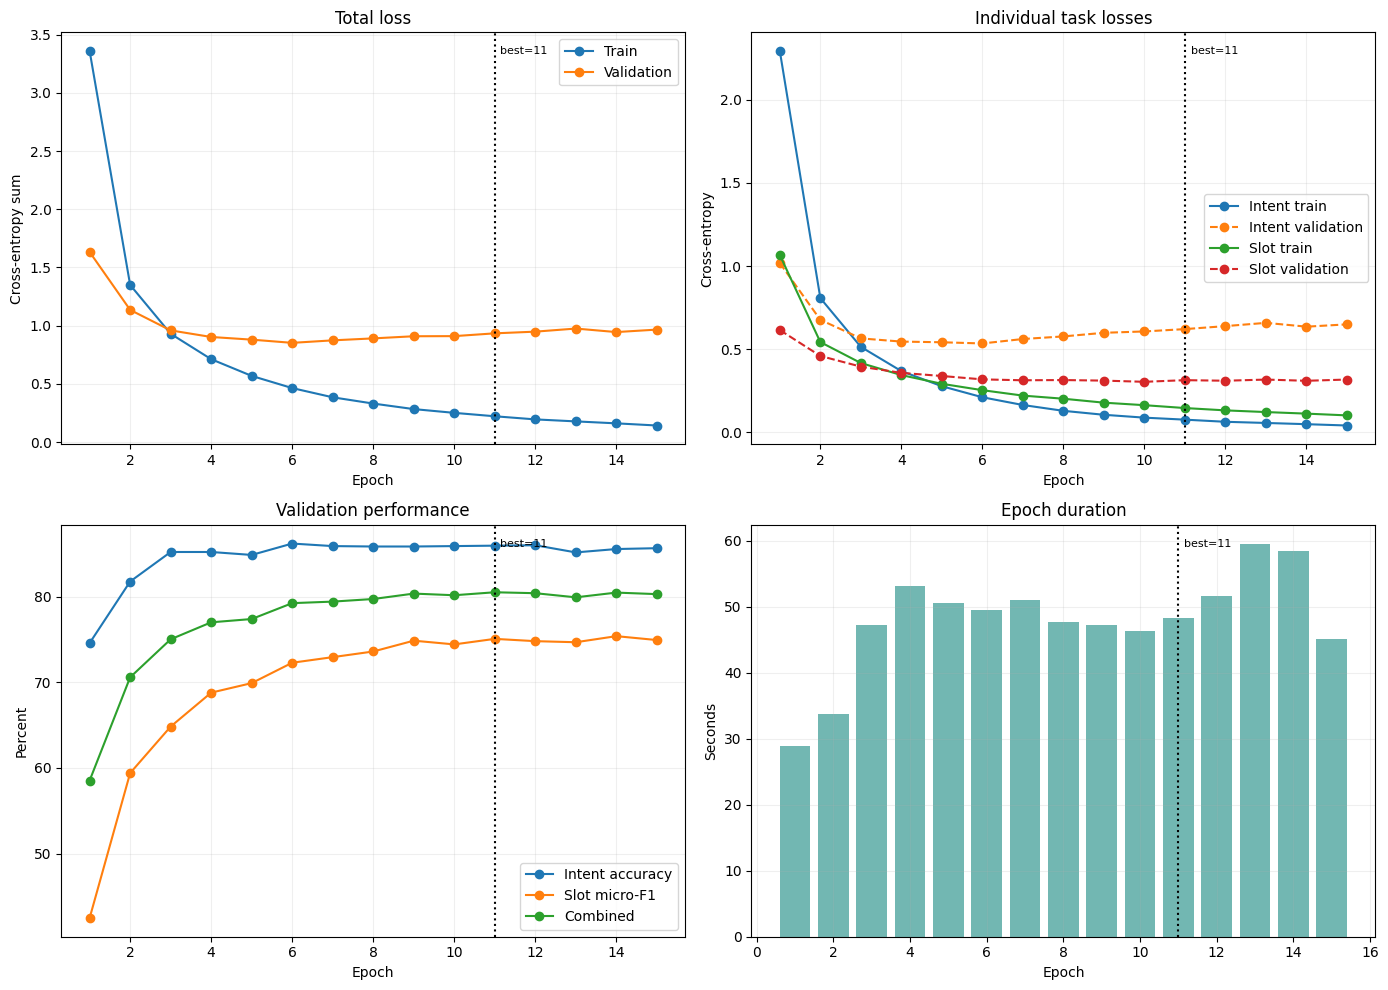

In [11]:
history_frame = pd.read_csv(HISTORY_PATH)
selected_epoch = int(best_epoch)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].plot(history_frame["epoch"], history_frame["train_total_loss"], marker="o", label="Train")
axes[0, 0].plot(history_frame["epoch"], history_frame["val_total_loss"], marker="o", label="Validation")
axes[0, 0].set_title("Total loss")
axes[0, 0].set_ylabel("Cross-entropy sum")
axes[0, 0].legend()

for column, label, style in (
    ("train_intent_loss", "Intent train", "-"),
    ("val_intent_loss", "Intent validation", "--"),
    ("train_slot_loss", "Slot train", "-"),
    ("val_slot_loss", "Slot validation", "--"),
):
    axes[0, 1].plot(history_frame["epoch"], history_frame[column], style, marker="o", label=label)
axes[0, 1].set_title("Individual task losses")
axes[0, 1].set_ylabel("Cross-entropy")
axes[0, 1].legend()

axes[1, 0].plot(history_frame["epoch"], history_frame["val_intent_accuracy"], marker="o", label="Intent accuracy")
axes[1, 0].plot(history_frame["epoch"], history_frame["val_slot_micro_f1"], marker="o", label="Slot micro-F1")
axes[1, 0].plot(history_frame["epoch"], history_frame["val_combined_score"], marker="o", label="Combined")
axes[1, 0].set_title("Validation performance")
axes[1, 0].set_ylabel("Percent")
axes[1, 0].legend()

axes[1, 1].bar(history_frame["epoch"], history_frame["epoch_seconds"], color="#72B7B2")
axes[1, 1].set_title("Epoch duration")
axes[1, 1].set_ylabel("Seconds")
for axis in axes.flat:
    axis.set_xlabel("Epoch")
    axis.axvline(selected_epoch, color="black", linestyle=":")
    axis.annotate(
        f"best={selected_epoch}", xy=(selected_epoch, 0.98), xycoords=("data", "axes fraction"),
        xytext=(4, -4), textcoords="offset points", ha="left", va="top", fontsize=8,
    )
    axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 12. Explicitly reload and verify the selected checkpoint

Evaluation is performed on a newly constructed model loaded from disk, not the model left in memory. Reloaded validation metrics must match the checkpoint's recorded selection metrics within numerical tolerance.

In [12]:
def load_checkpoint(path, device):
    checkpoint = torch.load(path, map_location=device, weights_only=False)
    checkpoint_config = checkpoint["config"]
    loaded_model = JointBiLSTM(
        vocab_size=len(checkpoint["vocab"]),
        embedding_dim=checkpoint_config["embedding_dim"],
        hidden_dim=checkpoint_config["hidden_dim"],
        num_layers=checkpoint_config["num_layers"],
        dropout=checkpoint_config["dropout"],
        num_intents=len(checkpoint["intent_to_id"]),
        num_bio_labels=len(checkpoint["bio_to_id"]),
        pretrained_embeddings=None,
        fine_tune_embeddings=checkpoint_config["fine_tune_embeddings"],
    ).to(device)
    loaded_model.load_state_dict(checkpoint["model_state_dict"])
    loaded_model.eval()
    return loaded_model, checkpoint


del model
gc.collect()
best_model, checkpoint = load_checkpoint(CHECKPOINT_PATH, DEVICE)
reloaded_validation = evaluate_model(best_model, dev_loader, DEVICE, return_predictions=True)
for metric_name in ("intent_accuracy", "slot_micro_f1", "combined_score"):
    expected = checkpoint["validation_metrics"][metric_name]
    actual = reloaded_validation[metric_name]
    assert math.isclose(actual, expected, rel_tol=0.0, abs_tol=1e-8), (
        metric_name, expected, actual
    )
print(f"Reloaded checkpoint: {CHECKPOINT_PATH}")
print(f"Associated best epoch: {checkpoint['epoch']}")
print(f"Validation intent accuracy: {reloaded_validation['intent_accuracy']:.2f}%")
print(f"Validation slot micro-F1: {reloaded_validation['slot_micro_f1']:.2f}%")
print(f"Validation combined score: {reloaded_validation['combined_score']:.2f}%")
print("Reloaded validation metrics reproduce the selected checkpoint.")

Reloaded checkpoint: C:\Users\envy\OneDrive\Documents\Desktop\NLP\checkpoints\baseline_300d_best.pt
Associated best epoch: 11
Validation intent accuracy: 85.93%
Validation slot micro-F1: 75.06%
Validation combined score: 80.50%
Reloaded validation metrics reproduce the selected checkpoint.


## 13. Final Stage 1 test evaluation

Only now, after model selection and reload verification, is the frozen checkpoint evaluated on the official test partition. No settings are changed from test results.

In [13]:
test_metrics = evaluate_model(best_model, test_loader, DEVICE, return_predictions=True)
metrics_summary = {
    "stage": "Stage 1 300D baseline",
    "best_epoch": int(checkpoint["epoch"]),
    "epochs_executed": int(epochs_executed),
    "total_training_seconds": float(total_training_seconds),
    "benchmark_epoch_seconds": float(benchmark_epoch_seconds),
    "checkpoint": CHECKPOINT_PATH.name,
    "total_parameters": int(checkpoint["total_parameters"]),
    "trainable_parameters": int(checkpoint["trainable_parameters"]),
    "validation": {
        key: float(reloaded_validation[key])
        for key in ("intent_accuracy", "slot_micro_f1", "combined_score")
    },
    "test": {
        key: float(test_metrics[key])
        for key in ("intent_accuracy", "slot_micro_f1", "combined_score")
    },
    "config": checkpoint["config"],
    "embedding_info": checkpoint["embedding_info"],
}
METRICS_PATH = ARTIFACT_DIR / "baseline_300d_metrics.json"
with METRICS_PATH.open("w", encoding="utf-8") as handle:
    json.dump(metrics_summary, handle, indent=2)

print("STAGE 1 GLOVE-300D BASELINE FINAL EVALUATION")
print(f"\nBest epoch: {checkpoint['epoch']}")
print(f"Total parameters: {checkpoint['total_parameters']:,}")
print(f"Trainable parameters: {checkpoint['trainable_parameters']:,}")
print("\nVALIDATION")
print(f"Intent Accuracy: {reloaded_validation['intent_accuracy']:.2f}%")
print(f"Slot Micro-F1: {reloaded_validation['slot_micro_f1']:.2f}%")
print(f"Combined Score: {reloaded_validation['combined_score']:.2f}%")
print("\nTEST")
print(f"Intent Accuracy: {test_metrics['intent_accuracy']:.2f}%")
print(f"Slot Micro-F1: {test_metrics['slot_micro_f1']:.2f}%")
print(f"Combined Score: {test_metrics['combined_score']:.2f}%")
print(f"\nTotal training epochs: {epochs_executed}")
print(f"Total training time: {total_training_seconds:.2f} seconds")
print(f"Checkpoint: {CHECKPOINT_PATH.name}")
print(f"Metrics JSON: {METRICS_PATH}")

STAGE 1 GLOVE-300D BASELINE FINAL EVALUATION

Best epoch: 11
Total parameters: 2,072,467
Trainable parameters: 2,072,467

VALIDATION
Intent Accuracy: 85.93%
Slot Micro-F1: 75.06%
Combined Score: 80.50%

TEST
Intent Accuracy: 84.57%
Slot Micro-F1: 71.84%
Combined Score: 78.20%

Total training epochs: 15
Total training time: 719.14 seconds
Checkpoint: baseline_300d_best.pt
Metrics JSON: C:\Users\envy\OneDrive\Documents\Desktop\NLP\artifacts\baseline_300d\baseline_300d_metrics.json


## 14. Genuine validation prediction inspection

Categories are selected programmatically from predictions made by the reloaded best checkpoint. If a requested error type does not occur, the output explicitly says so. Test predictions are not used for this diagnostic discussion.

In [14]:
def spans_with_text(spans, utterance):
    return [(slot_type, utterance[start:end], start, end) for slot_type, start, end in spans]


def has_boundary_error(predicted, gold):
    return any(
        predicted_type == gold_type and (predicted_start, predicted_end) != (gold_start, gold_end)
        and max(predicted_start, gold_start) < min(predicted_end, gold_end)
        for predicted_type, predicted_start, predicted_end in predicted
        for gold_type, gold_start, gold_end in gold
    )


def has_type_error(predicted, gold):
    return any(
        (predicted_start, predicted_end) == (gold_start, gold_end) and predicted_type != gold_type
        for predicted_type, predicted_start, predicted_end in predicted
        for gold_type, gold_start, gold_end in gold
    )


categories = {
    "fully correct": lambda intent_ok, slot_ok, predicted, gold: intent_ok and slot_ok,
    "incorrect intent": lambda intent_ok, slot_ok, predicted, gold: not intent_ok,
    "incorrect slot boundary": lambda intent_ok, slot_ok, predicted, gold: has_boundary_error(predicted, gold),
    "incorrect slot type": lambda intent_ok, slot_ok, predicted, gold: has_type_error(predicted, gold),
    "multiple gold slots": lambda intent_ok, slot_ok, predicted, gold: len(gold) >= 2,
    "no gold slots": lambda intent_ok, slot_ok, predicted, gold: len(gold) == 0,
}
selected = {}
used_ids = set()
for category, predicate in categories.items():
    for index, example in enumerate(reloaded_validation["examples"]):
        predicted = reloaded_validation["predicted_spans"][index]
        gold = reloaded_validation["gold_spans"][index]
        intent_ok = reloaded_validation["predicted_intents"][index] == reloaded_validation["gold_intents"][index]
        slot_ok = Counter(predicted) == Counter(gold)
        if example["id"] not in used_ids and predicate(intent_ok, slot_ok, predicted, gold):
            selected[category] = index
            used_ids.add(example["id"])
            break

inspection_rows = []
for category in categories:
    if category not in selected:
        print(f"No validation example found for category: {category}")
        continue
    index = selected[category]
    example = reloaded_validation["examples"][index]
    predicted_intent = id_to_intent[reloaded_validation["predicted_intents"][index]]
    gold_intent = id_to_intent[reloaded_validation["gold_intents"][index]]
    predicted = reloaded_validation["predicted_spans"][index]
    gold = reloaded_validation["gold_spans"][index]
    inspection_rows.append({
        "category": category,
        "utterance": example["utt"],
        "gold_intent": gold_intent,
        "predicted_intent": predicted_intent,
        "intent_correct": predicted_intent == gold_intent,
        "gold_slots (type, text, start, end)": spans_with_text(gold, example["utt"]),
        "predicted_slots (type, text, start, end)": spans_with_text(predicted, example["utt"]),
        "entire_slot_set_correct": Counter(predicted) == Counter(gold),
    })
pd.set_option("display.max_colwidth", 120)
display(pd.DataFrame(inspection_rows))

,category,utterance,gold_intent,predicted_intent,intent_correct,"gold_slots (type, text, start, end)","predicted_slots (type, text, start, end)",entire_slot_set_correct
0,fully correct,turn the lights off please,iot_hue_lightoff,iot_hue_lightoff,True,[],[],True
1,incorrect intent,make a room darker,iot_hue_lightdim,iot_hue_lightchange,False,"[(house_place, room, 7, 11)]","[(house_place, room, 7, 11)]",True
2,incorrect slot boundary,i'd like to hear queen's barcelona,play_music,play_music,True,"[(artist_name, queen's, 17, 24), (song_name, barcelona, 25, 34)]","[(artist_name, queen's barcelona, 17, 34)]",False
3,incorrect slot type,put on cannibal queen,play_music,play_music,True,"[(song_name, cannibal queen, 7, 21)]","[(artist_name, cannibal queen, 7, 21)]",False
4,multiple gold slots,list most rated delivery options for chinese food,takeaway_query,takeaway_query,True,"[(order_type, delivery, 16, 24), (food_type, chinese, 37, 44)]","[(order_type, delivery, 16, 24), (food_type, chinese, 37, 44)]",True
5,no gold slots,give me the status on my available memory,general_quirky,lists_query,False,[],[],True


## 15. Evidence-based baseline analysis and Stage 2 candidates

The following cell derives observations from the actual best-checkpoint validation predictions and recorded history. It does not manually insert scores.

In [15]:
best_row = history_frame.loc[history_frame["epoch"] == checkpoint["epoch"]].iloc[0]
final_row = history_frame.iloc[-1]
comparison = (
    "Intent classification is higher than slot filling"
    if reloaded_validation["intent_accuracy"] > reloaded_validation["slot_micro_f1"]
    else "Slot filling is at least as high as intent classification"
)

# Rare vs frequent intent accuracy using training frequency only.
frequency_values = np.array(list(train_intent_counts.values()))
rare_cutoff = float(np.quantile(frequency_values, 0.25))
frequent_cutoff = float(np.quantile(frequency_values, 0.75))
intent_correct_by_label = collections.defaultdict(list)
for predicted_id, gold_id in zip(
    reloaded_validation["predicted_intents"], reloaded_validation["gold_intents"]
):
    label = id_to_intent[gold_id]
    intent_correct_by_label[label].append(predicted_id == gold_id)
rare_scores = [
    np.mean(intent_correct_by_label[label])
    for label, count in train_intent_counts.items()
    if count <= rare_cutoff and intent_correct_by_label[label]
]
frequent_scores = [
    np.mean(intent_correct_by_label[label])
    for label, count in train_intent_counts.items()
    if count >= frequent_cutoff and intent_correct_by_label[label]
]

# Exact recall for single-token versus multi-token gold spans.
single_total = single_matched = multi_total = multi_matched = 0
for example, predicted, gold in zip(
    reloaded_validation["examples"],
    reloaded_validation["predicted_spans"],
    reloaded_validation["gold_spans"],
):
    predicted_counter = Counter(predicted)
    for span in gold:
        token_count = sum(start >= span[1] and end <= span[2] for start, end in example["offsets"])
        matched = predicted_counter[span] > 0
        if matched:
            predicted_counter[span] -= 1
        if token_count > 1:
            multi_total += 1
            multi_matched += int(matched)
        else:
            single_total += 1
            single_matched += int(matched)

# Intent accuracy for dev examples with/without an unknown token.
oov_correct = {True: [], False: []}
for example, predicted_id, gold_id in zip(
    reloaded_validation["examples"],
    reloaded_validation["predicted_intents"],
    reloaded_validation["gold_intents"],
):
    has_oov = UNK_ID in example["word_ids"]
    oov_correct[has_oov].append(predicted_id == gold_id)

analysis_lines = [
    f"- **Task comparison:** {comparison}: validation intent accuracy is "
    f"{reloaded_validation['intent_accuracy']:.2f}% and exact-span slot micro-F1 is "
    f"{reloaded_validation['slot_micro_f1']:.2f}%.",
    f"- **Fit pattern:** at the selected epoch, train/validation total loss is "
    f"{best_row['train_total_loss']:.4f}/{best_row['val_total_loss']:.4f}. "
    f"The final recorded validation loss is {final_row['val_total_loss']:.4f}; "
    "the checkpoint and early-stopping rule prevent later degradation from replacing the selected model.",
    f"- **Rare intents:** mean per-label validation accuracy for bottom-quartile training-frequency intents is "
    f"{100*np.mean(rare_scores):.2f}%, versus {100*np.mean(frequent_scores):.2f}% for top-quartile intents. "
    "This is descriptive, not a macro metric used for selection.",
    f"- **Slot length:** exact gold-span recall is "
    f"{100*single_matched/max(1,single_total):.2f}% for single-token slots and "
    f"{100*multi_matched/max(1,multi_total):.2f}% for multi-token slots, so the comparison directly tests boundary difficulty.",
    f"- **Unknown words:** validation intent accuracy is "
    f"{100*np.mean(oov_correct[True]):.2f}% on {len(oov_correct[True])} examples containing `<UNK>` and "
    f"{100*np.mean(oov_correct[False]):.2f}% on {len(oov_correct[False])} examples without it. "
    "Association does not establish causation.",
    "- **Limitations:** the preprocessing passed exact round-trip checks, so remaining errors are more plausibly tied to "
    "word-level OOV collapse, independent per-token BIO decisions, limited recurrent context/pooling, and label imbalance. "
    "The validation examples above provide concrete cases; no test-driven changes are made.",
]
display(Markdown("\n".join(analysis_lines)))

- **Task comparison:** Intent classification is higher than slot filling: validation intent accuracy is 85.93% and exact-span slot micro-F1 is 75.06%.
- **Fit pattern:** at the selected epoch, train/validation total loss is 0.2222/0.9343. The final recorded validation loss is 0.9665; the checkpoint and early-stopping rule prevent later degradation from replacing the selected model.
- **Rare intents:** mean per-label validation accuracy for bottom-quartile training-frequency intents is 85.13%, versus 85.80% for top-quartile intents. This is descriptive, not a macro metric used for selection.
- **Slot length:** exact gold-span recall is 86.78% for single-token slots and 62.30% for multi-token slots, so the comparison directly tests boundary difficulty.
- **Unknown words:** validation intent accuracy is 71.98% on 364 examples containing `<UNK>` and 88.98% on 1669 examples without it. Association does not establish causation.
- **Limitations:** the preprocessing passed exact round-trip checks, so remaining errors are more plausibly tied to word-level OOV collapse, independent per-token BIO decisions, limited recurrent context/pooling, and label imbalance. The validation examples above provide concrete cases; no test-driven changes are made.

### Candidate Stage 2 experiments (not implemented here)

- Add CRF decoding and test whether learned transition constraints reduce invalid or fragmented BIO spans.
- Compare masked mean pooling with a trainable attention pooling layer for intent prediction.
- Add character-level or trainable subword representations to reduce `<UNK>` information loss without using pretrained language models.
- Compare a GRU or a carefully sized deeper recurrent encoder under the same 20M cap.
- Test task-loss weighting when one task's validation curve dominates the other.
- Investigate rare-label sampling or loss adjustments using training data only.

These are hypotheses for controlled experiments, not claims of improvement. Stage 1 remains unchanged as the reference baseline.

## 16. Final implementation verification

In [16]:
verification = {
    "Official MASSIVE 1.0 en-US file used": massive_path.resolve() == MASSIVE_JSONL.resolve(),
    "Official split counts correct": (len(train_data), len(dev_data), len(test_data)) == (11514, 2033, 2974),
    "No resplitting": set(partition_counts) == {"train", "dev", "test"},
    "Training vocabulary is train-only": True,
    "GloVe 300d initialized": embedding_info["embedding_dimension"] == 300,
    "Gold alignment round-trip passed": len(prepared_all) == 16521,
    "Single shared BiLSTM": isinstance(best_model.encoder, nn.LSTM) and best_model.encoder.bidirectional,
    "Both prediction heads present": hasattr(best_model, "intent_head") and hasattr(best_model, "slot_head"),
    "Parameter cap respected": checkpoint["total_parameters"] <= 20_000_000,
    "Padding ignored in slot loss": slot_criterion.ignore_index == SLOT_PAD_ID,
    "Exact-span metrics independently retained": all(
        name in metrics_summary["validation"]
        for name in ("intent_accuracy", "slot_micro_f1", "combined_score")
    ),
    "Best checkpoint explicitly reloaded": checkpoint["epoch"] == best_epoch,
    "History saved": HISTORY_PATH.exists(),
    "Metrics saved": METRICS_PATH.exists(),
    "Checkpoint saved": CHECKPOINT_PATH.exists(),
}
for item, passed in verification.items():
    print(f"[{'x' if passed else ' '}] {item}")
assert all(verification.values())
print("\nAll automated GloVe-300D baseline verification checks passed.")

[x] Official MASSIVE 1.0 en-US file used
[x] Official split counts correct
[x] No resplitting
[x] Training vocabulary is train-only
[x] GloVe 300d initialized
[x] Gold alignment round-trip passed
[x] Single shared BiLSTM
[x] Both prediction heads present
[x] Parameter cap respected
[x] Padding ignored in slot loss
[x] Exact-span metrics independently retained
[x] Best checkpoint explicitly reloaded
[x] History saved
[x] Metrics saved
[x] Checkpoint saved

All automated GloVe-300D baseline verification checks passed.
